# ROI_processing

In [45]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

In [3]:
summary_list

[]

In [24]:
import os
import pandas as pd

# Define base output directory
base_figures_dir = "/media/sergio/Meninges/troutpy/parameter_tuning/saisnsc/xenium_msbrain_5k/figures"

# Initialize lists to collect data
summary_list = []
xrna_metadata_list = []

# Iterate through each parameter folder
for param_suffix in os.listdir(base_figures_dir):
    folder_path = os.path.join(base_figures_dir, param_suffix)
    folder_path = os.path.join(folder_path, param_suffix)
    summary_path = os.path.join(folder_path, "pipeline_summary.csv")
    xrna_metadata_path = os.path.join(folder_path, "pipeline_xrna_metadata.csv")

    if os.path.isfile(summary_path) and os.path.isfile(xrna_metadata_path):
        # Read and annotate summary
        summary_df = pd.read_csv(summary_path)
        summary_df["param_set"] = param_suffix
        summary_list.append(summary_df)

        # Read and annotate xrna metadata
        xrna_df = pd.read_csv(xrna_metadata_path)
        proportion = xrna_df[["extracellular_proportion"]]
        proportion.columns = [param_suffix]
        xrna_metadata_list.append(proportion)

# Combine all
combined_summary = pd.concat(summary_list, ignore_index=True)
combined_xrna_metadata = pd.concat(xrna_metadata_list, axis=1)

##  Combine xrna proportions across runs

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# filter xrna metadata
combined_xrna_metadata = combined_xrna_metadata[np.sum(combined_xrna_metadata.isna(), axis=1) == 0]
# Compute cosine similarity between parameter sets (columns)
cos_sim_matrix = cosine_similarity(combined_xrna_metadata.T)
# Turn it into a labeled DataFrame
cos_sim_df = pd.DataFrame(cos_sim_matrix, index=combined_xrna_metadata.columns, columns=combined_xrna_metadata.columns)

<Figure size 600x500 with 0 Axes>

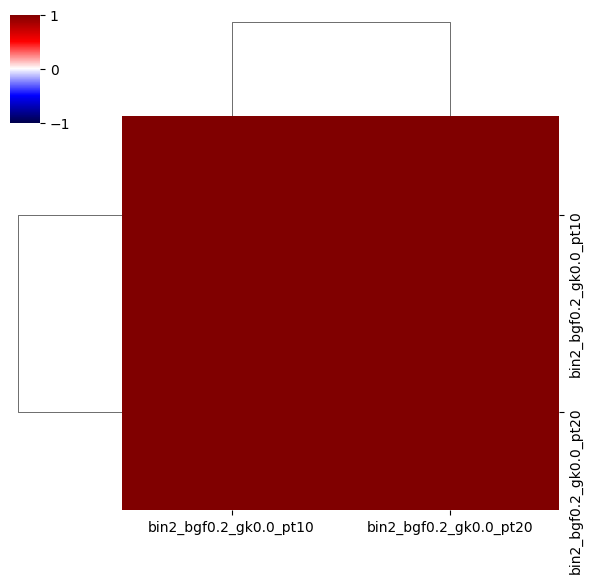

In [59]:
plt.figure(figsize=(6, 5))
sns.clustermap(
    cos_sim_df,
    vmin=-1,
    vmax=1,
    cmap="seismic",
    figsize=(6, 6),
)

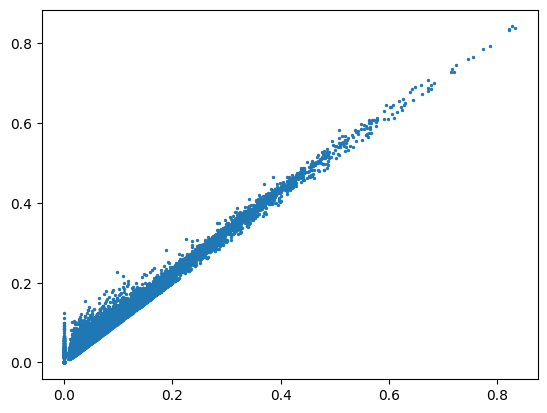

In [27]:
plt.scatter(combined_xrna_metadata.iloc[:, 0], combined_xrna_metadata.iloc[:, 1], s=2)

### Plot propotion of exRNA identified

In [ ]:
combined_summary["proportion_of_cell_like"] = (
    1 - combined_summary["proportion_of_segmented"] - combined_summary["proportion_of_extracellular"]
)
combined_summary.index = combined_summary["param_set"]
combined_summary.pop("param_set")

<Axes: ylabel='param_set'>

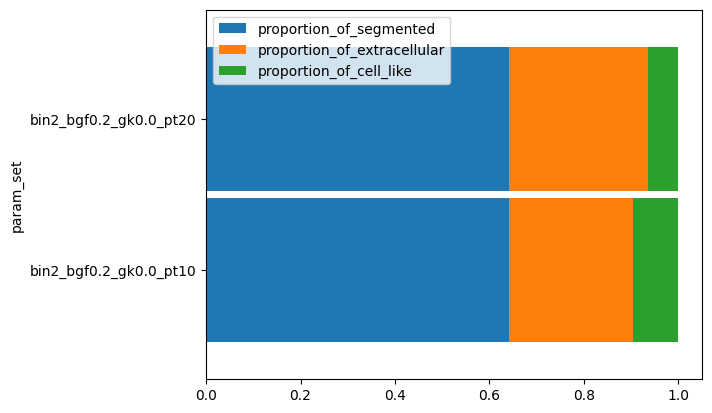

In [56]:
# plot combined summary as bar plot
combined_summary.plot(kind="barh", stacked=True, width=0.95)

In [ ]:
# Save if needed
combined_summary.to_csv("/media/sergio/Meninges/troutpy/parameter_tuning/combined_summary.csv", index=False)
combined_xrna_metadata.to_csv(
    "/media/sergio/Meninges/troutpy/parameter_tuning/combined_xrna_metadata.csv", index=False
)

print("Combined files saved.")